# Fraud Detection Using Machine Learning
**Data Science Project 2**

## Aim
The aim of this project is to build machine learning models that can identify fraudulent credit-card transactions. The dataset is highly imbalanced, so I will use SMOTE on training data and compare Logistic Regression with Random Forest.

**Dataset:** Credit Card Fraud Detection (Kaggle)  
https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


## 1. Import the libraries
These libraries are used to read the data, make graphs, train the models and check their performance.

In [ ]:
%pip -q install imbalanced-learn

In [ ]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

RANDOM_STATE = 42
print("Libraries are ready.")

## 2. Upload and read the dataset
The Kaggle download is usually a ZIP file. This cell extracts it and reads `creditcard.csv`.

In [ ]:

import pandas as pd
import zipfile
import os
from google.colab import files

# Upload your dataset
uploaded = files.upload()

csv_path = None

for filename in uploaded.keys():

    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            csv_files = [
                name for name in z.namelist()
                if name.lower().endswith(".csv")
            ]

            if not csv_files:
                raise ValueError("No CSV file found inside the ZIP.")

            # Extract the CSV file
            csv_name = csv_files[0]
            z.extract(csv_name, "/content")
            csv_path = os.path.join("/content", csv_name)

    elif filename.lower().endswith(".csv"):
        csv_path = os.path.join("/content", filename)

    if csv_path is not None:
        break

if csv_path is None:
    raise ValueError("Please upload archive.zip or creditcard.csv.")

# Load the dataset
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Saving archive.zip to archive.zip
Dataset loaded successfully!
Rows and columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Check the data
First, I check the column types, missing values, duplicate rows and the number of transactions in each class.

In [ ]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass counts:")
print(df["Class"].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 4. Show the class imbalance
Class 0 means a legitimate transaction and class 1 means a fraudulent transaction. The chart shows why accuracy by itself would not be enough to judge the model.

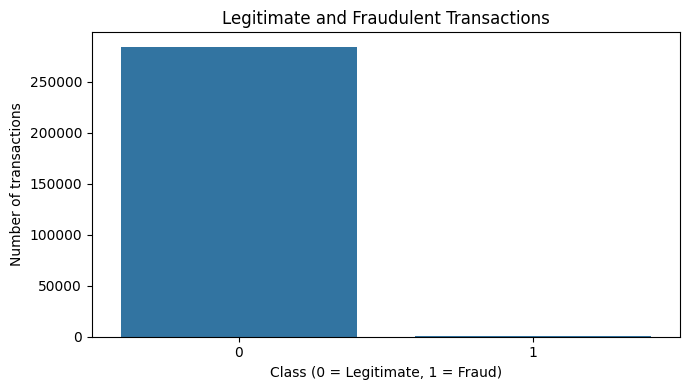

Fraud percentage: 0.1727 %


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count legitimate and fraudulent transactions
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values)

plt.title("Legitimate and Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of transactions")

plt.tight_layout()
plt.show()

print("Fraud percentage:", round(df["Class"].mean() * 100, 4), "%")


## 5. Separate the features and target
`X` contains the transaction columns. `y` contains the label that the model will predict.

In [ ]:
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


## 6. Split the data
I keep 20% of the data for testing. I split before applying SMOTE so the test set stays unchanged.

In [ ]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
X = df.drop("Class", axis=1)
y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())


Training rows: 227845
Testing rows: 56962

Training labels:
Class
0    227451
1       394
Name: count, dtype: int64

Testing labels:
Class
0    56864
1       98
Name: count, dtype: int64


## 7. Set up the models

SMOTE makes synthetic examples of the minority class. It is inside each pipeline, so it runs on training data during fitting and is not applied to the test set.

To keep Random Forest training manageable in a standard Colab session, I use a stratified sample of the training data for that model. Logistic Regression uses the full training set. The final evaluation for both models uses the same untouched test set.

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
lr_model = Pipeline(steps=[
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])
rf_sample_size = min(60000, len(X_train))

X_rf_train, _, y_rf_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=rf_sample_size,
    random_state=RANDOM_STATE,
    stratify=y_train
)
rf_model = Pipeline(steps=[
    ("smote", SMOTE(
        random_state=RANDOM_STATE,
        sampling_strategy=0.2
    )),
    ("model", RandomForestClassifier(
        n_estimators=40,
        max_depth=14,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Logistic Regression will use all training rows.")
print("Random Forest training sample:", len(X_rf_train))




Logistic Regression will use all training rows.
Random Forest training sample: 60000


## 8. Train the models
This cell may take a few minutes. Let it finish before moving to the next cell.

In [ ]:

RANDOM_STATE = 42

lr_model = Pipeline(steps=[
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

rf_model = Pipeline(steps=[
    ("smote", SMOTE(
        random_state=RANDOM_STATE,
        sampling_strategy=0.2
    )),
    ("model", RandomForestClassifier(
        n_estimators=40,
        max_depth=14,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

print("Both models created successfully!")




Both models created successfully!


In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)
print("Logistic Regression trained successfully!")

print("Training Random Forest...")
rf_model.fit(X_rf_train, y_rf_train)
print("Random Forest trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!
Training Random Forest...
Random Forest trained successfully!


## 9. Evaluate the models
Precision shows how many flagged transactions were actually fraud. Recall shows how much of the fraud was found. ROC-AUC checks how well the model separates the two classes across different thresholds.

In [ ]:

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = (y_pred, y_prob)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print("\n", name)
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))



 Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

Confusion matrix:
[[55397  1467]
 [    8    90]]

 Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.78      0.84      0.81        98

    accuracy                           1.00     56962
   macro avg       0.89      0.92      0.90     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix:
[[56841    23]
 [   16    82]]


,Precision,Recall,ROC-AUC
Model,,,
Logistic Regression,0.0578,0.9184,0.9708
Random Forest,0.7810,0.8367,0.9723


## 10. Compare the models
The graph makes it easier to compare the three required metrics. A better model depends on whether missed fraud or false alarms are more costly.

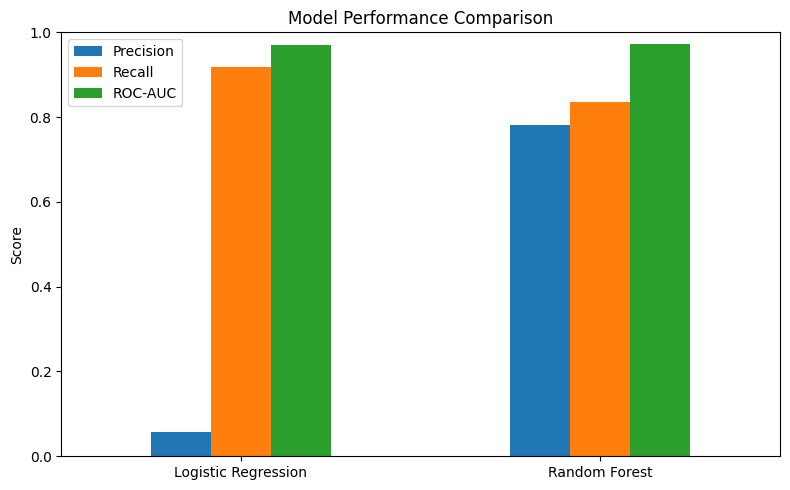

In [ ]:
ax = results_df.plot(kind="bar", figsize=(8, 5), ylim=(0, 1))
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. ROC curves and confusion matrices

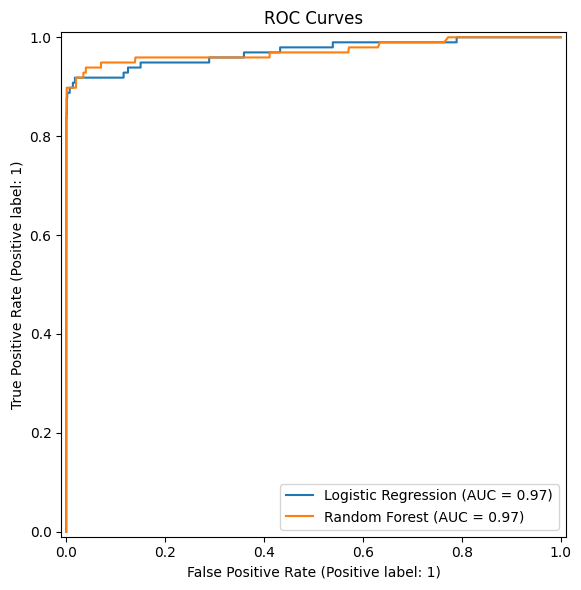

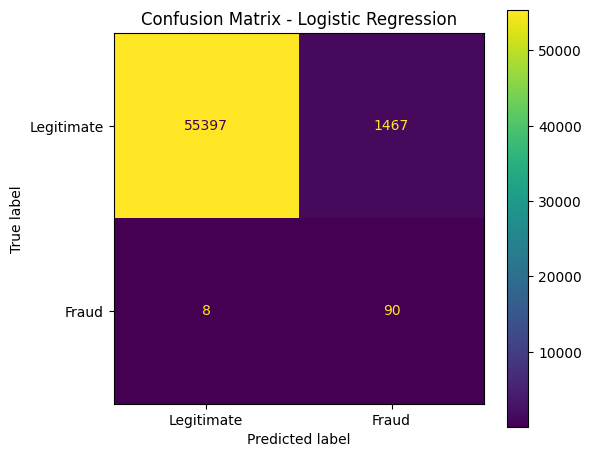

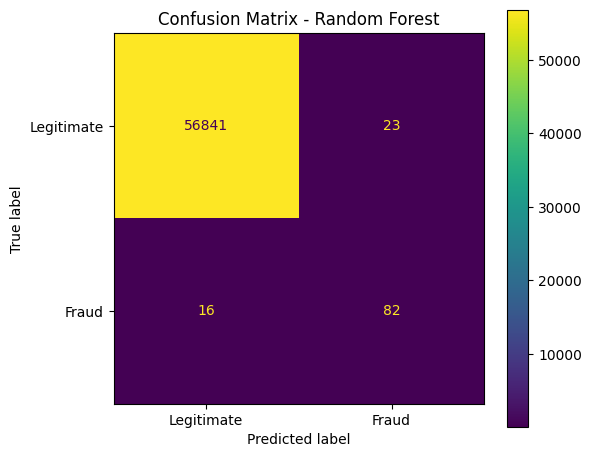

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.set_title("ROC Curves")
plt.tight_layout()
plt.show()

# Confusion matrices
for name, (y_pred, y_prob) in predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Legitimate", "Fraud"],
        values_format="d",
        ax=ax
    )

    ax.set_title("Confusion Matrix - " + name)
    plt.tight_layout()
    plt.show()


## 12. Tune Random Forest

This search tests a small number of parameter combinations on a smaller sample of the training set, to keep runtime reasonable. SMOTE remains inside the pipeline. The final model is then checked against the original test set.

In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score
tune_size = min(25000, len(X_train))

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=tune_size,
    random_state=RANDOM_STATE,
    stratify=y_train
)
rf_tune_pipeline = Pipeline(steps=[
    ("smote", SMOTE(
        random_state=RANDOM_STATE,
        sampling_strategy=0.2
    )),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
param_dist = {
    "model__n_estimators": [30, 40, 60],
    "model__max_depth": [10, 14, 18, None],
    "model__min_samples_leaf": [1, 2, 4]
}
rf_search = RandomizedSearchCV(
    estimator=rf_tune_pipeline,
    param_distributions=param_dist,
    n_iter=4,
    scoring="roc_auc",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1
)

print("Tuning Random Forest...")
rf_search.fit(X_tune, y_tune)

print("Best parameters:", rf_search.best_params_)
print("Best cross-validation ROC-AUC:", round(rf_search.best_score_, 4))


Tuning Random Forest...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__n_estimators': 40, 'model__min_samples_leaf': 2, 'model__max_depth': 14}
Best cross-validation ROC-AUC: 0.9855


## 13. Test the tuned model
These are the final test-set scores for the tuned Random Forest. The test data has not been used during tuning.

In [ ]:

from sklearn.metrics import (
    precision_score, recall_score,
    roc_auc_score, confusion_matrix
)
import pandas as pd
best_model = rf_search.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:, 1]
tuned_results = {
    "Model": "Tuned Random Forest",
    "Precision": precision_score(
        y_test, tuned_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, tuned_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, tuned_prob)
}

for metric in ["Precision", "Recall", "ROC-AUC"]:
    print(f"{metric}: {tuned_results[metric]:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, tuned_pred))
all_results = pd.concat([
    results_df.reset_index(),
    pd.DataFrame([tuned_results])
], ignore_index=True).set_index("Model")

display(all_results.round(4))


Precision: 0.8119
Recall: 0.8367
ROC-AUC: 0.9567

Confusion matrix:
[[56845    19]
 [   16    82]]


,Precision,Recall,ROC-AUC
Model,,,
Logistic Regression,0.0578,0.9184,0.9708
Random Forest,0.7810,0.8367,0.9723
Tuned Random Forest,0.8119,0.8367,0.9567


## 14. Save the results
The table is saved as a CSV file, which can be included with the submission.

In [ ]:
all_results.to_csv("fraud_detection_results.csv")
files.download("fraud_detection_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusion

After running the notebook, use the actual scores from the results table to complete the paragraph below. Do not leave the bracketed parts in the final submission.

In this project, I used the Credit Card Fraud Detection dataset to train models for identifying fraudulent transactions. The dataset had many more legitimate transactions than fraudulent ones, so I used SMOTE on training data to help address the imbalance. I trained Logistic Regression and Random Forest and compared them using Precision, Recall and ROC-AUC. I also tuned the Random Forest settings and evaluated the tuned model on the test set.

Based on my results, **[write the model with the best result for your chosen metric]** had a **[Precision / Recall / ROC-AUC]** score of **[insert your score]**. Recall matters because missed fraud is a problem, while Precision matters because false alarms can affect legitimate customers. The best model should therefore be selected by looking at all three metrics rather than accuracy alone.

### Limitations
Random Forest uses a stratified sample of the training data to reduce runtime. The models are evaluated on the same held-out test set, but the difference in training data size should be kept in mind when comparing them.